# Train X3D-M on NTU RGB (16 classes)
Run the three cells from top to bottom.

**Before the first run**
1. On your own computer: `uv run src/rgb_vs_skeleton/shrink_data.py` (makes `data/processed/rgb.zip`).
2. Upload to Google Drive as `MyDrive/Project_DL`: `src/`, `configs/`, `notebooks/`, `data/processed/rgb.zip`, `data/processed/splits.csv`, `data/processed/skeleton_cache.npz`.
3. In Colab: **Runtime → Change runtime type → T4 GPU**.
4. In Colab: key icon on the left → add a secret named `WANDB_API_KEY` → switch on notebook access.

In [1]:
# ============ 1. SETUP: Google Drive, packages, wandb key, videos, GPU ============
import os, shutil, sys
from pathlib import Path

import torch
from google.colab import drive, userdata

drive.mount("/content/drive")

PROJECT = Path("/content/drive/MyDrive/Project_DL")   # <- the folder you uploaded to Google Drive
EXP = "exp1"                                           # <- which yaml in configs/experiments/RGB_/experiment/ to use

os.chdir(PROJECT)                                      # all paths in the yaml files are relative to this folder
sys.path.insert(0, str(PROJECT / "src/rgb_vs_skeleton"))

# packages that Colab does not have (torch, torchvision and opencv are already installed)
!pip -q install hydra-core pytorchvideo wandb

# wandb key: stored in Colab under the key icon on the left (name: WANDB_API_KEY), never typed into the notebook
os.environ["WANDB_API_KEY"] = userdata.get("WANDB_API_KEY")

# videos: unpack data/processed/rgb.zip (made by shrink_data.py) to Colab's fast local disk.
# The local disk is emptied when the session ends, so this runs again in every new session (a few minutes).
RGB_ZIP = PROJECT / "data/processed/rgb.zip"
RGB_DIR = Path("/content/data/rgb")
if not RGB_ZIP.exists():
    raise FileNotFoundError(f"{RGB_ZIP} not found: run shrink_data.py on your computer and upload the zip to Google Drive")
if not RGB_DIR.exists():
    print(f"unpacking {RGB_ZIP.name} ({RGB_ZIP.stat().st_size / 1024**3:.1f} GB) to the local disk ...")
    shutil.unpack_archive(RGB_ZIP, RGB_DIR.parent)
print(f"videos: {len(list(RGB_DIR.glob('*.mp4')))} clips in {RGB_DIR}")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("NO GPU: choose Runtime -> Change runtime type -> T4 GPU, then run this cell again")

Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
unpacking rgb.zip (0.4 GB) to the local disk ...
videos: 15050 clips in /content/data/rgb
GPU: Tesla T4


[split] loaded data/processed/splits.csv
[rgb train]   9200 clips ( 64%)  shape (9200, 3, 16, 224, 224)  | 575 clips per class | 16 performers
[rgb val  ]    912 clips (  6%)  shape (912, 3, 16, 224, 224)  | 57 clips per class | 4 performers
[rgb test ]   4368 clips ( 30%)  shape (4368, 3, 16, 224, 224)  | 273 clips per class | 20 performers

one batch: clips (8, 3, 16, 224, 224) = (batch, colours, frames, height, width), labels [3, 5, 9, 5, 6, 14, 6, 9]
loading this batch took 1.8 s  ->  about 34 min of video loading per epoch


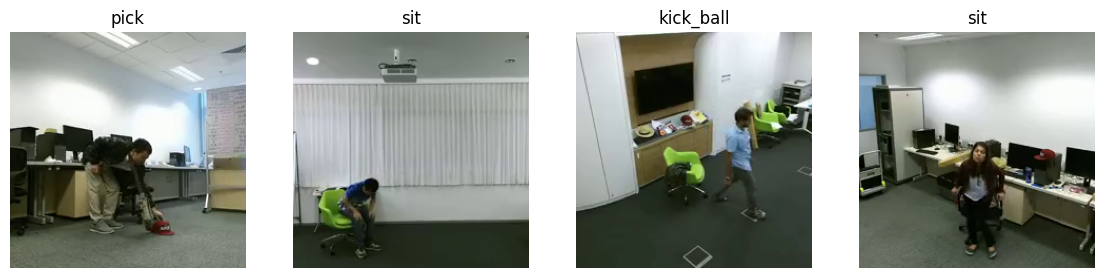

In [2]:
# ============ 2. DATA: build the loaders and look at the input of the model ============
import time

import matplotlib.pyplot as plt
from omegaconf import OmegaConf

from loaders import X3D_MEAN, X3D_STD, print_split_summary, rgb_dataloader

cfg = OmegaConf.load("configs/main_config.yaml")
exp = OmegaConf.load(f"configs/experiments/RGB_experiments/{EXP}.yaml")
actions = [int(c.ntu60) for c in cfg.classes]
class_names = [c.hmdb for c in cfg.classes]

loaders, datasets = rgb_dataloader(
    video_dir=RGB_DIR, actions=actions, split_file=cfg.split_file,
    num_frames=exp.num_frames, side=exp.side, size=exp.size,
    batch_size=exp.batch_size, num_workers=exp.num_workers)
print_split_summary(datasets, "rgb")

start = time.perf_counter()
clips, labels = next(iter(loaders["train"]))
seconds = time.perf_counter() - start
print(f"\none batch: clips {tuple(clips.shape)} = (batch, colours, frames, height, width), labels {labels.tolist()}")
print(f"loading this batch took {seconds:.1f} s  ->  about {seconds * len(loaders['train']) / 60:.0f} min of video loading per epoch")

# the middle frame of the first 4 clips, exactly as the model sees them (normalisation undone for display)
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, clip, label in zip(axes, clips, labels):
    frame = clip[:, clip.shape[1] // 2].permute(1, 2, 0) * X3D_STD[0] + X3D_MEAN[0]
    ax.imshow(frame.clamp(0, 1))
    ax.set_title(class_names[label])
    ax.axis("off")
plt.show()

In [ ]:
# ============ 3. TRAINING: runs src/rgb_vs_skeleton/train_RGB.py with the chosen experiment yaml ============
# Hyper-parameters: edit configs/experiments/RGB_/experiment/<EXP>.yaml (double-click it in the file browser on the left).
# Progress: watch the lines below, or the live charts at wandb.ai. Stopping this cell is safe: run it again to continue.
!python src/rgb_vs_skeleton/train_RGB.py +exp={EXP} processed_RGB_FOLDER="{RGB_DIR}"

[config] experiment file: configs/experiments/RGB_experiments/exp1.yaml  (run name: x3d_m_exp1)
[split] loaded /content/drive/MyDrive/Project_DL/data/processed/splits.csv
[data] train 9200 clips, val 912 clips, clip shape (3, 16, 224, 224), device cuda
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Downloading: "https://dl.fbaipublicfiles.com/pytorchvideo/model_zoo/kinetics/X3D_M.pyth" to /root/.cache/torch/hub/checkpoints/X3D_M.pyth
[x3d] could not download the Kinetics weights (URLError) - using RANDOM weights
[resume] found /content/drive/MyDrive/Project_DL/models/x3d_m_exp1/last.pt: 1 epochs already done, best val acc 0.782
[plan] training epochs 2..16 of a 16-epoch schedule
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: milinkovicz (milinkovicz-hong-kong-university-of-science